# 01 · The NHS A&E data, and restating eight years of history onto today's NHS

**Question:** what is in NHS England's monthly A&E files, and what has to be fixed before
anything can be forecast?

**Source:** NHS England, *A&E Attendances and Emergency Admissions* monthly situation reports
(Accredited Official Statistics, Open Government Licence v3.0). One CSV per month, April 2018 to
October 2026, plus the October 2026 provider-to-ICB mapping.

Three things break a naive model:
1. **file formats drift** (column names change across years)
2. **trusts merge** (21 Type 1 providers disappear)
3. **trusts change how they record Type 1 attendances** when they open or close a co-located
   urgent treatment centre (32 recording changes at 25 trusts)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nhsae import viz
from nhsae.config import PANEL, PROC
from nhsae.ingest import load_icb_mapping, load_monthly
from nhsae.panel import MERGERS

viz.set_style()
pd.set_option("display.width", 140)
raw = load_monthly()
print(f"{len(raw):,} provider-months, {raw.month.nunique()} months "
      f"({raw.month.min():%b %Y} – {raw.month.max():%b %Y}), {raw.org_code.nunique()} organisation codes")

21,738 provider-months, 103 months (Apr 2018 – Oct 2026), 283 organisation codes


## 1. What a provider-month looks like
Every A&E provider reports attendances by department type, breaches of the 4-hour standard and
emergency admissions. **Type 1** = consultant-led 24-hour major emergency departments, the focus here.
Type 2 = single-specialty (eye, dental); "Other" = urgent treatment centres, walk-in centres, minor injury units.

In [2]:
cols = ["month", "org_code", "org_name", "att_type1", "att_other", "over4h_type1", "emadm_type1"]
raw.loc[raw.month == raw.month.max(), cols].sort_values("att_type1", ascending=False).head(5)

,month,org_code,org_name,att_type1,att_other,over4h_type1,emadm_type1
21684,2026-10-01,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,33937,14836,15000,10841
21731,2026-10-01,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,29939,1381,13311,8729
21586,2026-10-01,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,29632,12096,12687,5957
21597,2026-10-01,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,28894,8669,11320,9261
21598,2026-10-01,RAL,ROYAL FREE LONDON NHS FOUNDATION TRUST,28795,16704,8228,7434


The loader (`nhsae.ingest`) maps every historical header variant (for example `A&E attendances Type 1` vs
`Number of A&E attendances Type 1`) onto one schema, drops TOTAL rows, and runs a **data contract**:
no missing months, no duplicate provider-months, no negative counts.

In [3]:
by_type = raw.groupby("month")[["att_type1", "att_type2", "att_other"]].sum()
share = by_type.div(by_type.sum(axis=1), axis=0)
print("Share of all A&E attendances, latest month:")
print(share.iloc[-1].round(3).to_string())

Share of all A&E attendances, latest month:
att_type1    0.627
att_type2    0.023
att_other    0.350


## 2. Mergers: restating history on today's trusts
21 Type 1 providers stopped reporting under their old code because they merged. Each is mapped to
its successor. The check is that predecessor + successor is **continuous** across the merger month.

In [4]:
m = pd.DataFrame([{"retired": k, "successor": v[0], "from": v[1], "note": v[2]} for k, v in MERGERS.items()])
m.head(8)

,retired,successor,from,note
0,RGQ,RDE,2018-07,Ipswich + Colchester -> East Suffolk & North E...
1,RR1,RRK,2018-07,Heart of England -> University Hospitals Birmi...
2,RJF,RTG,2018-07,Burton + Derby -> UH Derby & Burton
3,RLN,R0B,2019-04,City Hospitals Sunderland -> South Tyneside & ...
4,RE9,R0B,2019-04,South Tyneside -> South Tyneside & Sunderland
5,RQ6,REM,2019-10,Royal Liverpool & Broadgreen -> Liverpool Univ...
6,RNL,RNN,2019-10,North Cumbria University Hospitals -> North Cu...
7,RQ8,RAJ,2020-04,Mid Essex -> Mid & South Essex


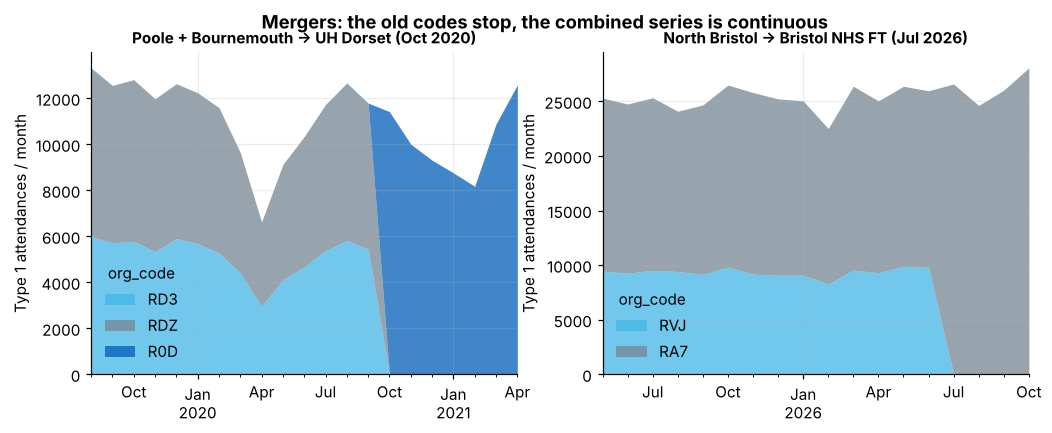

In [5]:
t1 = raw.pivot_table(index="month", columns="org_code", values="att_type1", aggfunc="sum").fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, (old, new, title) in zip(axes, [("RD3", "R0D", "Poole + Bournemouth → UH Dorset (Oct 2020)"),
                                        ("RVJ", "RA7", "North Bristol → Bristol NHS FT (Jul 2026)")]):
    olds = [k for k, v in MERGERS.items() if v[0] == new and (k == old or new == "R0D")]
    win = t1.loc[pd.Timestamp(MERGERS[old][1]) - pd.DateOffset(months=14): pd.Timestamp(MERGERS[old][1]) + pd.DateOffset(months=6)]
    win[olds + [new]].plot.area(ax=ax, alpha=0.75, color=[viz.NHS_LIGHT, viz.NHS_GREY, viz.NHS_BLUE][: len(olds) + 1], lw=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Type 1 attendances / month")
fig.suptitle("Mergers: the old codes stop, the combined series is continuous", fontweight="bold")
viz.save(fig, "01_mergers")

## 3. Recording changes: the problem the data contract found
After the mergers were fixed, a contract check (no trust's Type 1 daily rate should jump more than 60%
in a month) still failed for two trusts. They hadn't merged. They had **reclassified attendances**:
patients streamed to a co-located urgent treatment centre move from "Type 1" to "Other".
Total activity barely moves; the Type 1 series steps.

`nhsae.reclass.detect` finds every such step: Type 1 moves by more than 15%, "Other" moves the opposite
way, and the two changes largely cancel.

In [6]:
events = pd.read_csv(PROC / "type1_reclassifications.csv", parse_dates=["month"])
print(f"{len(events)} recording changes at {events.trust_code.nunique()} trusts")
events[["trust_name", "month", "t1_change", "share_pre", "share_post", "factor"]].round(3).head(10)

32 recording changes at 25 trusts


/tmp/ipykernel_705/1869937855.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  events[["trust_name", "month", "t1_change", "share_pre", "share_post", "factor"]].round(3).head(10)


,trust_name,month,t1_change,share_pre,share_post,factor
0,Isle Of Wight NHS Trust,2019-11-01,-0.340,0.823,0.564,0.685
1,Isle Of Wight NHS Trust,2024-01-01,0.156,0.623,0.692,1.111
2,Kingston And Richmond NHS Foundation Trust,2019-04-01,-0.279,1.000,0.713,0.713
3,"Barking, Havering And Redbridge University Hos...",2018-08-01,-0.221,0.858,0.681,0.793
4,Chesterfield Royal Hospital NHS Foundation Trust,2021-12-01,-0.505,0.650,0.351,0.540
5,Chesterfield Royal Hospital NHS Foundation Trust,2023-01-01,0.573,0.402,0.687,1.711
6,James Paget University Hospitals NHS Foundatio...,2021-10-01,-0.197,0.986,0.871,0.883
7,Guy'S And St Thomas' NHS Foundation Trust,2023-10-01,-0.154,0.841,0.690,0.820
8,St George'S University Hospitals NHS Foundatio...,2022-08-01,-0.216,0.922,0.772,0.838
9,Northern Lincolnshire And Goole NHS Foundation...,2024-05-01,-0.418,0.989,0.572,0.578


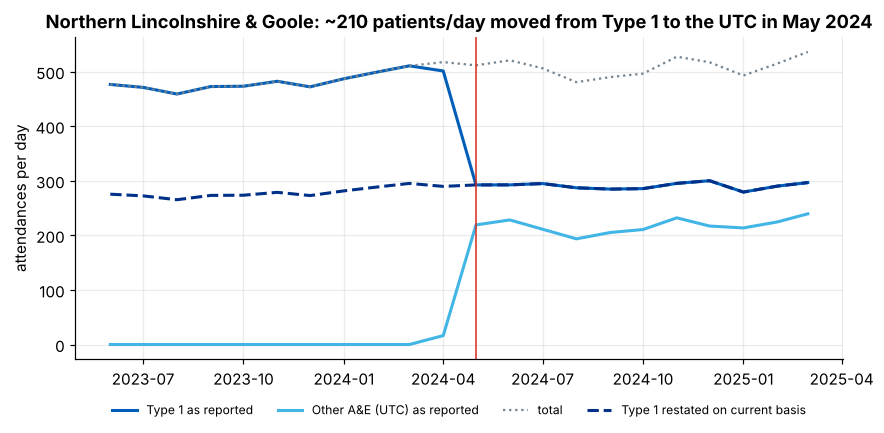

In [7]:
rjl = raw[raw.org_code == "RJL"].set_index("month")[["att_type1", "att_other"]].loc["2023-06":"2025-03"]
rjl = rjl.div(rjl.index.days_in_month, axis=0)
panel = pd.read_csv(PANEL, parse_dates=["month"])
rest = panel[panel.trust_code == "RJL"].set_index("month").attendances.loc["2023-06":"2025-03"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(rjl.index, rjl.att_type1, color=viz.NHS_BLUE, lw=2, label="Type 1 as reported")
ax.plot(rjl.index, rjl.att_other, color=viz.NHS_LIGHT, lw=2, label="Other A&E (UTC) as reported")
ax.plot(rjl.index, rjl.att_type1 + rjl.att_other, color=viz.NHS_GREY, ls=":", label="total")
ax.plot(rest.index, rest / rest.index.days_in_month, color=viz.NHS_DARK, ls="--", lw=2,
        label="Type 1 restated on current basis")
ax.axvline(pd.Timestamp("2024-05-01"), color=viz.NHS_RED, lw=1)
ax.set_title("Northern Lincolnshire & Goole: ~210 patients/day moved from Type 1 to the UTC in May 2024")
ax.set_ylabel("attendances per day")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
viz.save(fig, "01_reclassification")

Without the restatement, a model sees a 42% collapse in demand at this trust and forecasts it to keep
falling. With it, the series is continuous. The 4-hour model keeps the **reported** figures, because
breaches and attendances must be on the same basis to give a valid percentage.

## 4. The hierarchy
120 trusts with a Type 1 department in October 2026 and at least 3 years of history, mapped to
today's 36 ICBs and 7 NHS England regions.

In [8]:
icb = load_icb_mapping()
hier = pd.read_csv(PROC / "hierarchy.csv")
summary = hier.groupby("region_name").agg(ICBs=("icb_code", "nunique"), trusts=("trust_code", "size"))
summary.loc["England"] = summary.sum()
summary

,ICBs,trusts
region_name,,
East of England,3,13
London,4,17
Midlands,11,21
North East and Yorkshire,4,22
North West,3,18
South East,4,17
South West,7,12
England,36,120


In [9]:
eng = panel.groupby("month")[["attendances", "attendances_reported"]].sum()
print("Restatement changes the England total by "
      f"{(eng.attendances / eng.attendances_reported - 1).abs().max():.1%} at most in any month; "
      "it matters at trust level, not nationally.")

Restatement changes the England total by 1.2% at most in any month; it matters at trust level, not nationally.
